In [1]:
# Import packages
import sys
sys.path.append("./../") 

import shap
import torch
from torch.utils.data import DataLoader, Dataset
from matplotlib.colors import LinearSegmentedColormap

import numpy as np
import matplotlib.pyplot as plt

from scripts.utils import load_array, load_model

This notebook visualizes examples of KernelSHAP.

In [2]:
colors = ["#A338C4", '#248EF1', "#29BA10", '#F68D0E', '#F12476']

In [3]:
# Set data and model settings
dataset = 'turbofan'
data_path = './../data/prepared/' + dataset + '/'
task = 'regression'
bidirectional = False
device = 'cuda:0'
t = np.linspace(0, 100, 100)

In [4]:
# Set model path
model_path = './../models/' + dataset + '/' + '/uni_channel'
data_path = './../data/prepared/' + dataset + '/'

In [5]:
# Load background data
background_samples = load_array(data_path +  '/background_samples.pkl')
if len(background_samples.shape) == 2:
    background_samples = background_samples[:, :, None]

In [6]:
# Set class dictionary, mapping targets to labels
if dataset == 'fordA':
    class_dict = {0: 'Normal', 1: 'Anomalous'}
elif dataset == 'opportunity_uni':
    class_dict = {0:'Stand', 1:'Walk', 2:'Sit', 3:'Lie'}
else:
    class_dict = None

In [7]:
# Load data
X_train = load_array(data_path + '/X_train.pkl')
X_test = load_array(data_path +  '/X_test.pkl')

y_train = load_array(data_path +  '/y_train.pkl')
y_test = load_array(data_path +  '/y_test.pkl')

if len(X_train.shape) == 2:
    X_train = X_train[:, :, None]
    X_test = X_test[:, :, None]

In [8]:
model = load_model(model_path, task, bidirectional, X_train.shape[-1], class_dict, device, model_name='model_' + str(0) + '.pt')

In [9]:
class UnlabelledDataset(Dataset):
    "Barebones unlabelled dataset for SHAP wrapper"
    def __init__(self, x):
        self.x = x

    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, idx):
        return self.x[idx]

def shap_wrapper(np_array, model, batch_size=1024, softmax=True):
    "Wrapper around model to facilitate the SHAP package. Batchwise data processing"
    "prevents memory from running out"
    # Cast numpy array to tensor
    if len(np_array.shape) == 2:
        np_array = np_array[:, :, None]
    tensor = torch.tensor(np_array, dtype=torch.float32, device=device)

    # Create dataloader to facilitate batch processing
    dataset = UnlabelledDataset(tensor)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    # Pass batches through models and keep track of the result
    model.eval()
    output_list = []
    for i, data in enumerate(dataloader):
        with torch.no_grad():
            data = data.to(device)
            out = model(data)
            if softmax:
                out = torch.nn.Softmax(dim=-1)(out)
            out = out.cpu().numpy()
            output_list.append(out)
    output = np.concatenate(output_list, axis=0)
    return output

In [10]:
# Initialize SHAP explainer
if task == 'classification':
    softmax = True
else:
    softmax = False
explainer = shap.KernelExplainer(lambda x: shap_wrapper(x, model, softmax=softmax), background_samples[:, :, 0])


In [11]:
# Select sample to analyze
idx_select = 12
x_select = X_test[idx_select:idx_select + 1, :, 0]

In [12]:
# Calculate SHAP values
shap_values = explainer.shap_values(x_select)

  0%|          | 0/1 [00:00<?, ?it/s]

In [13]:
# Select results along class axis
if task == 'classification':
    class_select = 0
    shap_select = shap_values[0, :, class_select]
else:
    shap_select = shap_values

In [14]:
# Set Y limits of the plot
reach = np.max(np.abs(shap_select))
vmin = -reach
vmax = reach

Text(0.5, 1.0, 'KernelSHAP explanation')

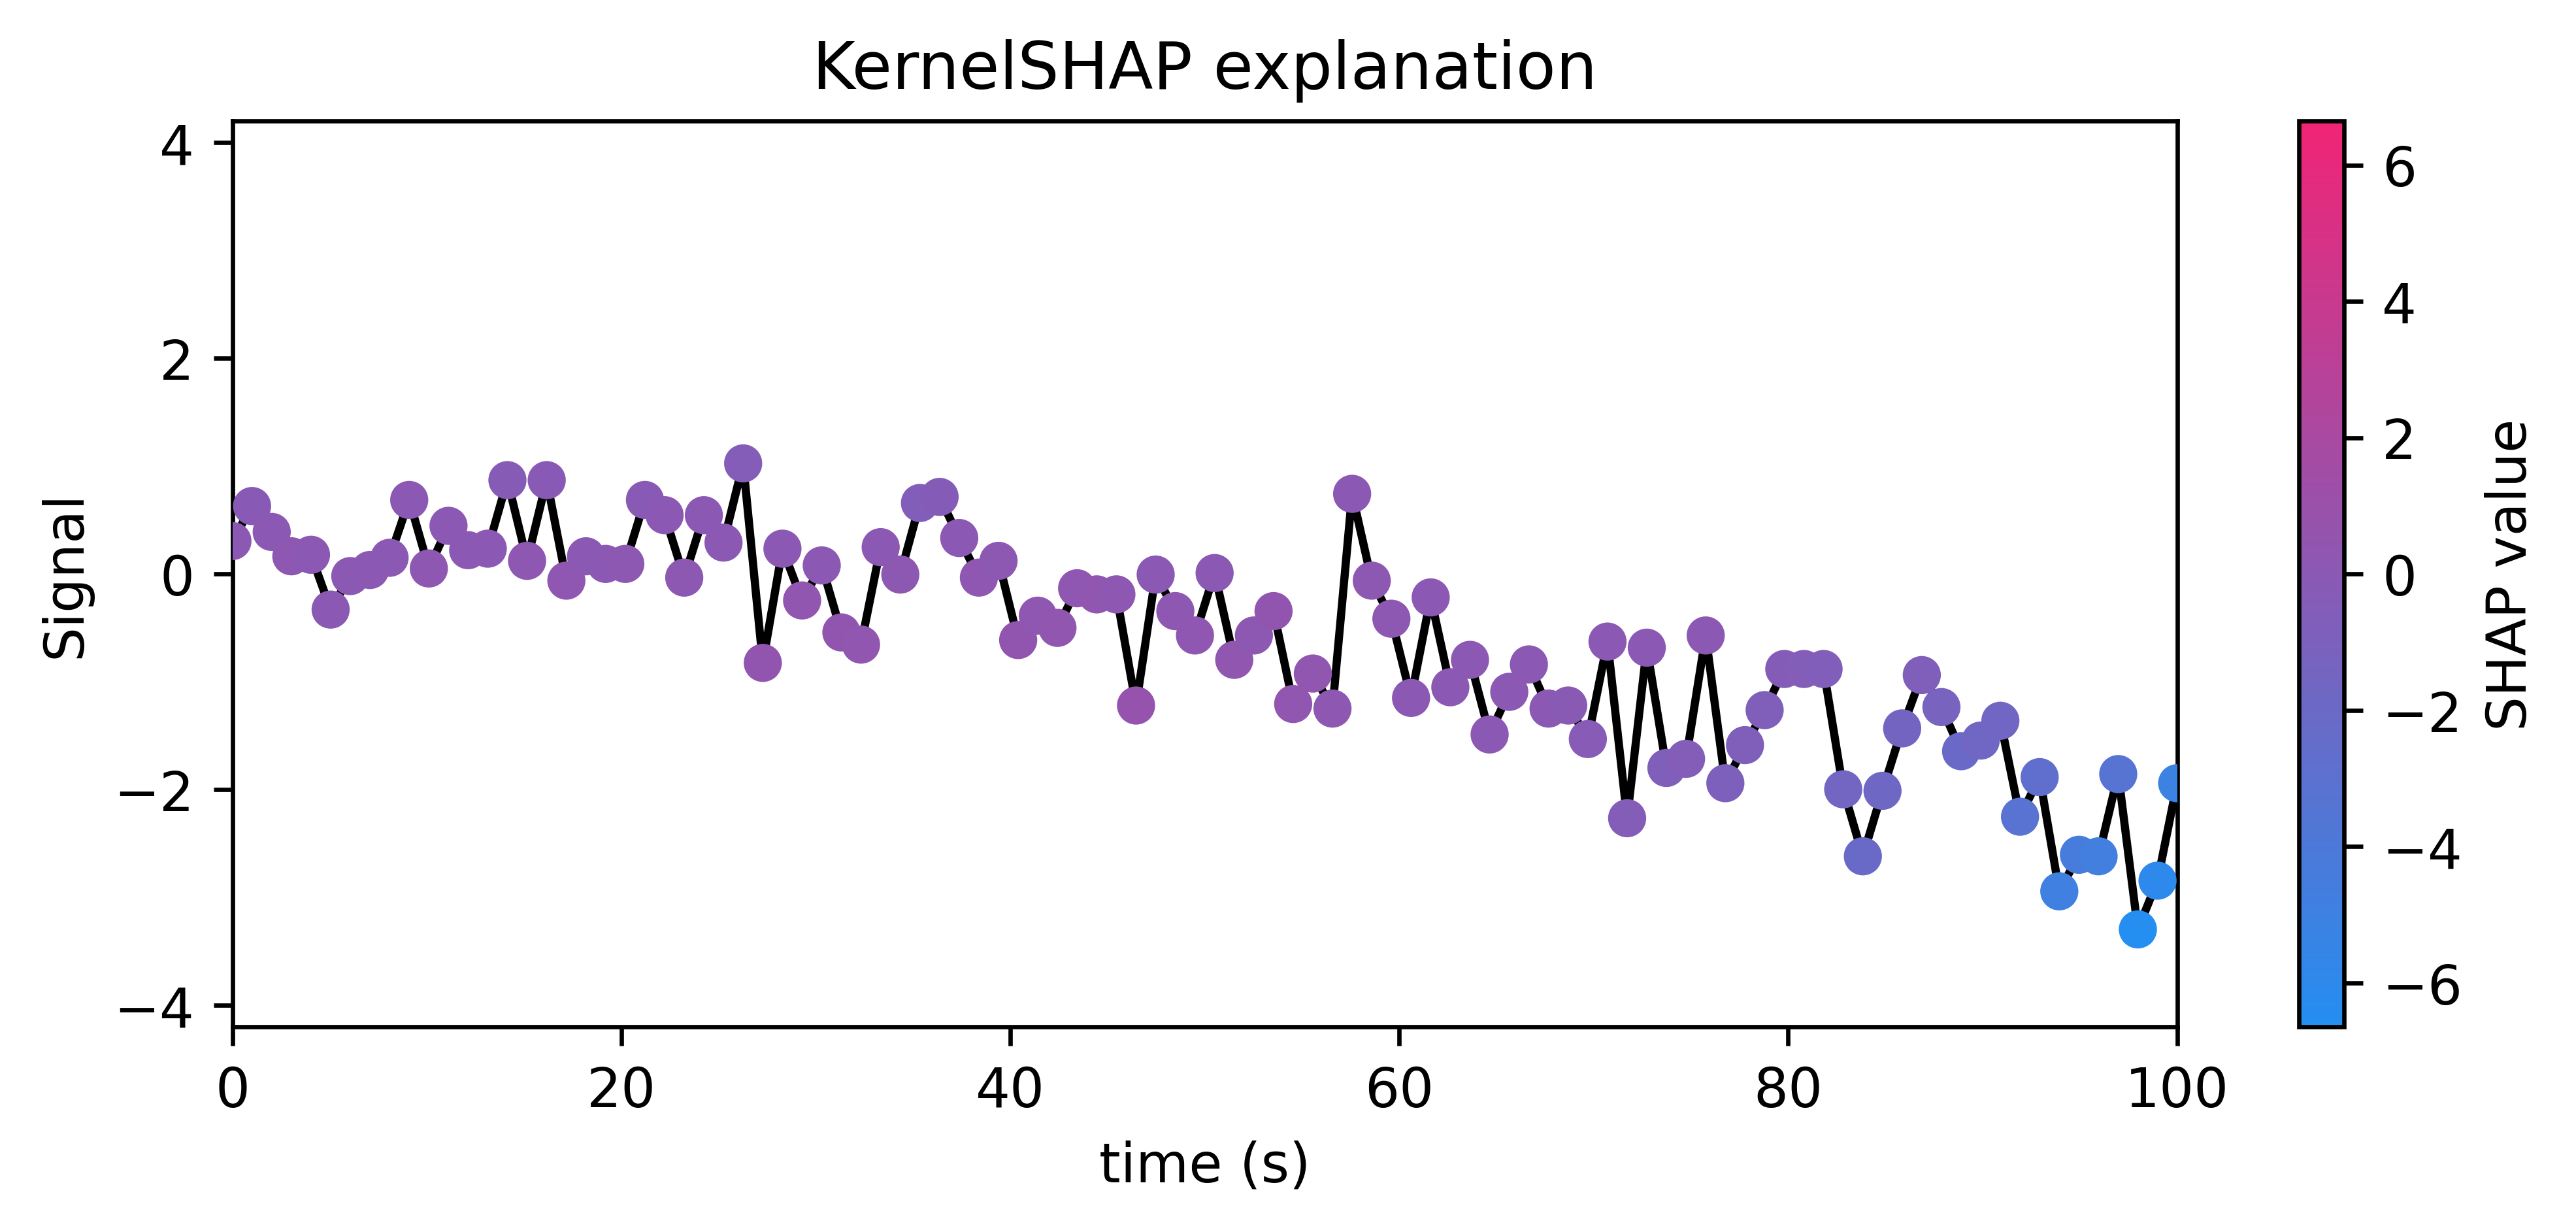

In [15]:
# Visualize KernelSHAP result
fig, ax = plt.subplots(dpi=600, figsize=(8, 3))
cmap = LinearSegmentedColormap.from_list('shap', [colors[1], colors[-1]])
ax.plot(t, x_select[0], color='k',zorder=1)
scatter = ax.scatter(t, x_select, c=shap_select, cmap=cmap, alpha=1,zorder=10, vmin=vmin, vmax=vmax)
plt.colorbar(scatter, label='SHAP value')
plt.xlim(0, 100)
plt.ylim(-4.2, 4.2)
plt.ylabel('Signal')
plt.xlabel('time (s)')
plt.title('KernelSHAP explanation')